# Pricing EDA: Product Selection for the United States and Canada

**SUMMARY**: This notebook checks currency consistency and selects products for pricing analysis using recent transaction activity and historical sales coverage. The results suggest that revenue is already recorded in a common currency across US and CA. We select Method 2 for the US (the six highest-scoring products from each of the five most active product families) and Method 1 for Canada (the 30 highest-scoring products overall).

## 1. Environment and Data Loading

### 1.1 Import Libraries and Locate Quarterly Files
Set `project_dir` to the project folder containing `raw data`. Run the notebook from the beginning so that all diagnostics use original financial values.

In [22]:
from pathlib import Path
import pandas as pd
from IPython.display import display
import hashlib
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root directory
project_dir = Path("/Users/AustinZhang/Desktop/Capstone")  # Change for your machine

# Raw data folder
raw_data_dir = project_dir / "raw data"

# Automatically collect all quarterly CSV files
files = sorted(raw_data_dir.glob("synthesized_FY*Q*.csv"))

print("Number of files found:", len(files))

Number of files found: 14


### 1.2 Combine Quarterly Transaction Files
Load all quarterly CSV files into one dataset. The source filename is retained for traceability, and every source row is preserved.

In [3]:
all_data = []

for file in files:
    temp = pd.read_csv(file, low_memory=False)
    temp["source_file"] = file.name
    all_data.append(temp)

df = pd.concat(all_data, ignore_index=True)

print("Number of files loaded:", len(files))
print("Combined rows:", df.shape[0])
print("Combined columns:", df.shape[1])

df.head()

Number of files loaded: 14
Combined rows: 11738282
Combined columns: 36


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


## 2. Data Preparation


In [5]:
eda = df.copy()

# Strip text columns while preserving missing values
text_columns = eda.select_dtypes(include="object").columns

for col in text_columns:
    if col != "source_file":
        eda[col] = eda[col].str.strip()

# Convert date columns
date_columns = ["order_date", "return_date", "ship_date", "week_begin"]

for col in date_columns:
    if col in eda.columns:
        eda[col] = pd.to_datetime(eda[col], errors="coerce")

# Convert numeric columns
numeric_columns = [
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
    "tax",
    "cost",
    "margin",
]

for col in numeric_columns:
    if col in eda.columns:
        eda[col] = pd.to_numeric(eda[col], errors="coerce")

print("EDA dataset shape:", eda.shape)
display(eda.head())

EDA dataset shape: (11738282, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,city,order_status,product_id,product_name,product_line,product_model,accessory_category,segment,product_type,country,sales_channel,order_units,revenue,invoice_quantity,invoice_revenue_country_currency,tax,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,******,Cancel,04PIQBL7GB,56AI3800RC ENGAGE WAY,Series Glide Line,Sub-Series Station Beam,NaN,Personal,Notebook,US,Direct,1.00,"1,767.00",NaN,NaN,NaN,0.00,"1,767.00",NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,******,Cancel,QLVX570,MONARCH Z&O LEGEND - SOLSTICE,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,US,Direct,1.00,30.00,NaN,NaN,NaN,0.00,30.00,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,******,Cancel,CMEG685,LIBERTY F&T KNIGHT - INTEGRAL,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,CA,Direct,1.00,0.00,NaN,NaN,NaN,0.00,0.00,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaT,NaT,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,******,Cancel,76ZTR7N407,CENTURY SO S83H X483774 2P V J99I,Series Stream Zone,Sub-Series Catalyst Gate,NaN,Enterprise,Desktop,US,Direct,1.00,616.00,NaN,NaN,NaN,0.00,616.00,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaT,NaT,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,******,Cancel,CMEG685,LIBERTY F&T KNIGHT - INTEGRAL,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,US,Direct,1.00,0.00,NaN,NaN,NaN,0.00,0.00,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


### 2.2 Inspect Country Labels and Retain Original Amounts
Review the country labels before separating US and CA records. A country label alone does not establish the currency of a financial field, so no exchange-rate conversion is applied.

In [6]:
# Currency remains unverified. Keep every original financial value unchanged.
print("Raw country labels:")
display(eda["country"].value_counts(dropna=False))

Raw country labels:


country
US    9664757
CA    2073525
Name: count, dtype: int64

## 3. Pricing Scope and Recent Activity Window

Include shipped Enterprise transactions with positive units and revenue and a valid ship or order date. Calculate ASP as `revenue / order_units`. Use the same six-month window for US and CA, anchored to the latest eligible pricing date.

In [7]:
# Keep only records relevant for pricing EDA
pricing_eda = eda[
    (eda["segment"] == "Enterprise")
    & (eda["order_status"] == "SHIPS")
    & (eda["order_units"] > 0)
    & (eda["revenue"] > 0)
].copy()

# Use shipped date if available, otherwise order date
pricing_eda["pricing_date"] = pricing_eda["ship_date"].fillna(pricing_eda["order_date"])

# Remove records without usable pricing date
pricing_eda = pricing_eda.dropna(subset=["pricing_date"])

# Calculate realized average selling price
pricing_eda["asp"] = pricing_eda["revenue"] / pricing_eda["order_units"]

# Define recent 6-month window
latest_date = pricing_eda["pricing_date"].max()
six_month_start = latest_date - pd.DateOffset(months=6)

recent = pricing_eda[pricing_eda["pricing_date"] >= six_month_start].copy()

print("Latest date:", latest_date)
print("Recent 6-month start:", six_month_start)
print("Rows in pricing scope:", len(pricing_eda))
print("Rows in recent 6-month scope:", len(recent))

Latest date: 2026-08-29 00:00:00
Recent 6-month start: 2026-02-28 00:00:00
Rows in pricing scope: 3839034
Rows in recent 6-month scope: 315923


## 4. Currency Consistency Diagnostics

Compare US and CA unit prices for matching products, months, price tiers, and sales channels. Also compare invoice-based and order-based unit prices to identify possible currency differences.
These comparisons provide evidence but do not confirm currency. Keep financial values unchanged until field-level currency definitions are verified.

In [8]:
# All diagnostics use the ORIGINAL amounts. No FX assumption or conversion.
def currency_diagnostics(pricing_data, min_rows=5, tolerance=0.05):
    data = pricing_data[pricing_data["country"].isin(["US", "CA"])].copy()
    data["month"] = data["pricing_date"].dt.to_period("M")
    data["unit_price_raw"] = data["revenue"] / data["order_units"]

    # Compare the same SKU in the same month, price tier and sales channel.
    # These diagnostics do not filter or modify the product-selection data.
    keys = ["product_id", "product_name", "month", "price_tier", "sales_channel"]
    valid = data.dropna(subset=["product_id", "product_name"])
    grouped = (
        valid.groupby(keys + ["country"], dropna=False)
        .agg(
            median_unit_price=("unit_price_raw", "median"),
            transaction_count=("unit_price_raw", "size"),
            units=("order_units", "sum"),
            revenue_raw=("revenue", "sum"),
        )
        .reset_index()
    )
    grouped["weighted_unit_price"] = grouped["revenue_raw"] / grouped["units"]
    us = grouped[grouped["country"].eq("US")].drop(columns="country")
    ca = grouped[grouped["country"].eq("CA")].drop(columns="country")
    pairs = us.merge(ca, on=keys, suffixes=("_US", "_CA"), validate="one_to_one")
    pairs["CA_over_US_median_price"] = (
        pairs["median_unit_price_CA"] / pairs["median_unit_price_US"]
    )
    pairs["CA_over_US_weighted_price"] = (
        pairs["weighted_unit_price_CA"] / pairs["weighted_unit_price_US"]
    )
    pairs["near_equal_5pct"] = (
        pairs["CA_over_US_median_price"].sub(1).abs().le(tolerance)
    )
    pairs["sufficient_rows"] = pairs["transaction_count_US"].ge(min_rows) & pairs[
        "transaction_count_CA"
    ].ge(min_rows)
    reliable = pairs[pairs["sufficient_rows"]]
    overview = pd.DataFrame(
        [
            {
                "matched_groups": len(pairs),
                "groups_with_min_rows_each_country": len(reliable),
                "min_rows_each_country": min_rows,
                "relative_tolerance": tolerance,
                "median_CA_over_US_price": reliable["CA_over_US_median_price"].median(),
                "ratio_p25": reliable["CA_over_US_median_price"].quantile(0.25),
                "ratio_p75": reliable["CA_over_US_median_price"].quantile(0.75),
                "share_near_equal": reliable["near_equal_5pct"].mean(),
            }
        ]
    )
    monthly = (
        reliable.groupby("month")
        .agg(
            matched_groups=("CA_over_US_median_price", "size"),
            median_CA_over_US_price=("CA_over_US_median_price", "median"),
            share_near_equal=("near_equal_5pct", "mean"),
        )
        .reset_index()
    )
    # The field name alone does not establish which currency revenue uses.
    # Unit-price comparison also accounts for differing invoice/order quantities.
    invoice = data[
        data["invoice_quantity"].gt(0) & data["invoice_revenue_country_currency"].gt(0)
    ].copy()
    invoice["invoice_unit_price_raw"] = (
        invoice["invoice_revenue_country_currency"] / invoice["invoice_quantity"]
    )
    invoice["invoice_unit_over_order_unit"] = (
        invoice["invoice_unit_price_raw"] / invoice["unit_price_raw"]
    )
    invoice["invoice_total_over_revenue"] = (
        invoice["invoice_revenue_country_currency"] / invoice["revenue"]
    )
    invoice_summary = (
        invoice.groupby("country")
        .agg(
            usable_invoice_rows=("invoice_unit_over_order_unit", "size"),
            median_invoice_unit_over_order_unit=(
                "invoice_unit_over_order_unit",
                "median",
            ),
            ratio_p25=("invoice_unit_over_order_unit", lambda x: x.quantile(0.25)),
            ratio_p75=("invoice_unit_over_order_unit", lambda x: x.quantile(0.75)),
            median_invoice_total_over_revenue=("invoice_total_over_revenue", "median"),
        )
        .reindex(["US", "CA"])
    )
    scope_counts = data.groupby("country").size().reindex(["US", "CA"], fill_value=0)
    invoice_summary["pricing_rows"] = scope_counts
    invoice_summary["usable_invoice_rows"] = (
        invoice_summary["usable_invoice_rows"].fillna(0).astype(int)
    )
    invoice_summary["invoice_usable_share"] = invoice_summary[
        "usable_invoice_rows"
    ] / scope_counts.replace(0, np.nan)
    return {
        "overview": overview,
        "matched_prices": pairs,
        "monthly": monthly,
        "invoice_summary": invoice_summary.reset_index(),
    }


currency_checks = currency_diagnostics(pricing_eda)
for name in ["overview", "monthly", "invoice_summary"]:
    print(name)
    display(currency_checks[name])
display(
    currency_checks["matched_prices"]
    .sort_values(["sufficient_rows", "transaction_count_CA"], ascending=False)
    .head(30)
)

overview


,matched_groups,groups_with_min_rows_each_country,min_rows_each_country,relative_tolerance,median_CA_over_US_price,ratio_p25,ratio_p75,share_near_equal
0,60217,19325,5,0.05,0.99,0.94,1.02,0.56


monthly


,month,matched_groups,median_CA_over_US_price,share_near_equal
0,2023-04,414,1.00,0.60
1,2023-05,516,0.99,0.60
2,2023-06,507,1.01,0.63
3,2023-07,439,1.01,0.61
4,2023-08,580,1.00,0.60
5,2023-09,539,0.99,0.61
6,2023-10,485,0.99,0.59
7,2023-11,771,0.99,0.60
8,2023-12,581,1.00,0.58
9,2024-01,494,1.00,0.59


invoice_summary


,country,usable_invoice_rows,median_invoice_unit_over_order_unit,ratio_p25,ratio_p75,median_invoice_total_over_revenue,pricing_rows,invoice_usable_share
0,US,3240554,1.00,1.00,1.00,1.00,3246479,1.00
1,CA,592321,1.37,1.35,1.39,1.37,592555,1.00


,product_id,product_name,month,price_tier,sales_channel,median_unit_price_US,transaction_count_US,units_US,revenue_raw_US,weighted_unit_price_US,median_unit_price_CA,transaction_count_CA,units_CA,revenue_raw_CA,weighted_unit_price_CA,CA_over_US_median_price,CA_over_US_weighted_price,near_equal_5pct,sufficient_rows
43140,71MCDJ13BS,TANGO CNRUJZZ- EL MONARCH,2025-06,$0 - $299,Partner Program,31.39,15,15.00,552.31,36.82,14.60,960,"1,224.00","16,285.96",13.31,0.47,0.36,False,True
56177,97U5A3MX99,64V0N1L148 FALCON SKY,2023-11,$500 - $699,Direct,599.00,2457,"3,167.00","1,916,590.77",605.18,614.15,707,930.00,"571,563.17",614.58,1.03,1.02,True,True
15297,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2026-03,$0 - $299,Direct,132.99,2919,"5,547.00","741,854.90",133.74,138.23,634,"1,378.00","194,551.63",141.18,1.04,1.06,True,True
45710,77T98518VL,MOMENTUM IMPACTROP ZNJ-E FLOW N0,2023-11,$0 - $299,Direct,159.56,2509,"4,152.00","643,547.34",155.00,158.58,613,988.00,"153,954.55",155.82,0.99,1.01,True,True
15231,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2024-11,$0 - $299,Direct,159.99,2590,"4,961.00","803,922.68",162.05,154.66,579,"1,076.00","166,428.53",154.67,0.97,0.95,True,True
15293,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2026-02,$0 - $299,Direct,129.99,2797,"5,827.00","753,203.93",129.26,136.28,559,"1,046.00","143,706.13",137.39,1.05,1.06,True,True
47848,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,2024-12,$0 - $299,Direct,0.01,1546,"3,194.00","1,224.91",0.38,0.01,497,848.00,80.81,0.10,1.00,0.25,True,True
45732,77T98518VL,MOMENTUM IMPACTROP ZNJ-E FLOW N0,2024-03,$0 - $299,Direct,149.99,2442,"4,568.00","683,861.85",149.71,153.92,486,"1,023.00","153,170.87",149.73,1.03,1.00,True,True
45727,77T98518VL,MOMENTUM IMPACTROP ZNJ-E FLOW N0,2024-02,$0 - $299,Direct,149.99,2043,"3,598.00","531,185.83",147.63,152.07,481,903.00,"135,243.26",149.77,1.01,1.01,True,True
53312,8PK1H20941,STATION ELEMENT VITALKZZUZXQT SXE-TMWQ,2024-02,$0 - $299,Direct,22.00,2624,"2,624.00","57,060.20",21.75,20.76,481,481.00,"9,631.54",20.02,0.94,0.92,False,True


## 5. Core Product Scope

### 5.1 Review Recent Product-Type Activity
Summarize recent transaction counts, revenue, units, and product diversity by product type before applying the core-product filter.

In [9]:
# Review product types before filtering

product_type_summary = (
    recent.groupby("product_type", dropna=False)
    .agg(
        transaction_count=("product_type", "size"),
        revenue=("revenue", "sum"),
        order_units=("order_units", "sum"),
        product_count=("product_name", "nunique"),
        family_count=("product_family", "nunique"),
    )
    .reset_index()
)

product_type_summary["weighted_asp"] = (
    product_type_summary["revenue"] / product_type_summary["order_units"]
)

product_type_summary = product_type_summary.sort_values(
    "transaction_count", ascending=False
)

display(product_type_summary)

,product_type,transaction_count,revenue,order_units,product_count,family_count,weighted_asp
6,Services,100238,"20,222,474.64","174,000.00",711,2,116.22
1,Notebook,76737,"197,531,798.52","144,136.00",970,4,"1,370.45"
2,Options,70294,"11,275,515.12","124,091.00",420,2,90.86
9,Workstations,30637,"111,001,302.42","51,019.00",419,1,"2,175.69"
0,Desktop,14770,"29,066,661.38","26,880.00",176,2,"1,081.35"
8,Visuals,14137,"6,817,571.71","36,681.00",49,1,185.86
7,Shipping,7157,"318,882.28","7,157.00",3,1,44.56
5,Servers,1791,"7,610,442.46","2,114.00",113,2,"3,600.02"
10,NaN,83,"32,867.25",87.00,7,1,377.78
3,Phones,77,"22,407.98",85.00,8,1,263.62


In [10]:
# Section: Filter Core Product Types

core_product_types = ["Notebook", "Workstations", "Desktop", "Visuals", "Servers"]

pricing_eda_core = pricing_eda[
    pricing_eda["product_type"].isin(core_product_types)
].copy()

recent = recent[recent["product_type"].isin(core_product_types)].copy()

print("Rows in pricing scope:", len(pricing_eda))
print("Rows in core pricing scope:", len(pricing_eda_core))
print("Rows in recent 6-month scope:", len(recent))
print("Rows in recent core scope:", len(recent))

Rows in pricing scope: 3839034
Rows in core pricing scope: 1638438
Rows in recent 6-month scope: 138072
Rows in recent core scope: 138072


## 6. Country-Level Product Selection

Products are evaluated separately for the US and Canada using formula `0.5*coverage + 0.5*transaction`, an equally weighted score combining recent six-month transaction-count percentiles and historical coverage-rate percentiles. Coverage measures the share of observed months in which a product had transactions.
- Method 1: Select the 30 highest-scoring products within each country.
- Method 2: Identify the five families with the most recent transactions, then select the six highest-scoring products from each family.

Both methods are applied to each country, and the selected products are compared using revenue and order units.

In [11]:
def select_country_products(core_data, recent_data, country):
    pricing_eda_core = core_data[core_data["country"].eq(country)].copy()
    recent = recent_data[recent_data["country"].eq(country)].copy()
    # Section: Historical Coverage Metrics

    pricing_eda_core["month"] = pricing_eda_core["pricing_date"].dt.to_period("M")
    total_months = pricing_eda_core["month"].nunique()

    product_coverage = (
        pricing_eda_core.groupby("product_name", dropna=False)
        .agg(
            active_months=("month", "nunique"),
            full_period_transaction_count=("product_name", "size"),
            full_period_revenue=("revenue", "sum"),
            full_period_units=("order_units", "sum"),
            latest_transaction_date=("pricing_date", "max"),
        )
        .reset_index()
    )

    product_coverage["coverage_rate"] = product_coverage["active_months"] / total_months

    # Method 1 - Product-level selection using recent activity and historical coverage

    method1_candidates = (
        recent.groupby(["product_name", "product_family", "product_type"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
            price_tier_count=("price_tier", "nunique"),
        )
        .reset_index()
    )

    method1_candidates = method1_candidates.merge(
        product_coverage, on="product_name", how="left"
    )

    method1_candidates["selection_score"] = (
        method1_candidates["transaction_count"].rank(pct=True) * 0.5
        + method1_candidates["coverage_rate"].rank(pct=True) * 0.5
    )

    method1_candidates["weighted_asp"] = (
        method1_candidates["revenue"] / method1_candidates["order_units"]
    )

    method1_candidates["margin_rate"] = (
        method1_candidates["margin"] / method1_candidates["revenue"]
    )

    method1_top30_products = (
        method1_candidates.sort_values("selection_score", ascending=False)
        .head(30)
        .reset_index(drop=True)
    )

    # Check product families represented in Method 1

    method1_family_summary = (
        method1_top30_products.groupby("product_family", dropna=False)
        .agg(
            selected_products=("product_name", "nunique"),
            total_transactions=("transaction_count", "sum"),
            total_revenue=("revenue", "sum"),
            total_units=("order_units", "sum"),
        )
        .reset_index()
        .sort_values("total_transactions", ascending=False)
    )

    # Method 2 - Select Top 5 Families

    family_recent = (
        recent.groupby("product_family", dropna=False)
        .agg(
            transaction_count=("product_family", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
        )
        .reset_index()
    )

    family_recent["weighted_asp"] = (
        family_recent["revenue"] / family_recent["order_units"]
    )
    family_recent["margin_rate"] = family_recent["margin"] / family_recent["revenue"]

    method2_top5_families = (
        family_recent.sort_values("transaction_count", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    top5_family_names = method2_top5_families["product_family"].tolist()

    # Method 2 - Select Top 6 Products per Top Family using recent activity and historical coverage

    product_recent_all = (
        recent.groupby(["product_family", "product_name", "product_type"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
            price_tier_count=("price_tier", "nunique"),
        )
        .reset_index()
    )

    product_recent_all = product_recent_all.merge(
        product_coverage, on="product_name", how="left"
    )

    product_recent_all["selection_score"] = (
        product_recent_all["transaction_count"].rank(pct=True) * 0.5
        + product_recent_all["coverage_rate"].rank(pct=True) * 0.5
    )

    product_recent_all["weighted_asp"] = (
        product_recent_all["revenue"] / product_recent_all["order_units"]
    )

    product_recent_all["margin_rate"] = (
        product_recent_all["margin"] / product_recent_all["revenue"]
    )

    method2_top6_each_family = (
        product_recent_all[product_recent_all["product_family"].isin(top5_family_names)]
        .sort_values(["product_family", "selection_score"], ascending=[True, False])
        .groupby("product_family", dropna=False)
        .head(6)
        .reset_index(drop=True)
    )
    return {
        "product_coverage": product_coverage,
        "total_months": total_months,
        "method1_candidates": method1_candidates,
        "method1_top30_products": method1_top30_products,
        "method1_family_summary": method1_family_summary,
        "method2_top5_families": method2_top5_families,
        "method2_top6_each_family": method2_top6_each_family,
    }


country_results = {
    country: select_country_products(pricing_eda_core, recent, country)
    for country in ["US", "CA"]
}
us_top30 = country_results["US"]["method1_top30_products"]
canada_top30 = country_results["CA"]["method1_top30_products"]
for country, result in country_results.items():
    print(country, "historical observed months:", result["total_months"])
    print("Method 1 selected rows:", len(result["method1_top30_products"]))
    display(result["method1_top30_products"])
    print("Method 2 selected rows:", len(result["method2_top6_each_family"]))
    display(result["method2_top6_each_family"])

US historical observed months: 41
Method 1 selected rows: 30


,product_name,product_family,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,A77U-61(K04687BO9)85.0MNCO JGPZQCG-ERDK,Product Family Quest Lunar,Visuals,409,"122,964.42",727.00,"40,666.28",2,36,3173,"1,061,360.09","6,001.00",2026-08-28,0.88,0.97,169.14,0.33
1,58OUYK5D87 SIGNAL WAY,Product Family Solar Peak,Workstations,524,"2,021,933.10","1,187.00","-148,585.53",9,24,3463,"10,836,723.43","6,017.00",2026-05-02,0.59,0.97,"1,703.40",-0.07
2,38NJQE7C52 WILLOW SKY,Product Family Solar Peak,Workstations,566,"2,046,905.92",874.00,"-45,919.85",3,23,2165,"8,523,496.01","3,292.00",2026-08-28,0.56,0.97,"2,342.00",-0.02
3,EMBERFCKGPT X82,Product Family Quest Lunar,Visuals,381,"96,450.31",728.00,"17,038.79",1,28,4958,"1,454,798.73","10,668.00",2026-04-08,0.68,0.97,132.49,0.18
4,LI ON W78 RAY Z8 H7 35N 710K 65G,Product Family Knight Thrive,Notebook,382,"649,200.11",689.00,"101,947.41",5,25,4650,"6,170,405.85","8,631.00",2026-08-15,0.61,0.96,942.24,0.16
5,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Product Family Frame Road,Notebook,1839,"4,275,452.45","2,638.00","949,435.56",6,18,9774,"25,451,610.91","12,887.00",2026-04-22,0.44,0.96,"1,620.72",0.22
6,I THRIVE ZENITH CH - MOMENTUM,Product Family Harbor Momentum,Servers,272,"37,242.40",310.00,"-272,447.60",1,34,1311,"183,184.80","1,606.00",2026-08-28,0.83,0.96,120.14,-7.32
7,EL UN SOLSTICE U0-28 R3 Z5 42U 3W 71Y,Product Family Frame Road,Notebook,1047,"2,316,214.43","1,753.00","319,328.79",8,18,2932,"6,529,640.83","4,497.00",2026-08-14,0.44,0.96,"1,321.29",0.14
8,IN FR SENTINEL O8-94 C5 B7 01Z 006P 86P,Product Family Frame Road,Notebook,903,"2,485,194.43","1,619.00","541,982.72",8,18,3465,"7,350,600.71","4,618.00",2026-08-22,0.44,0.96,"1,535.02",0.22
9,A61L(P88238IC4)21MAWP OGEEJQU(CEQV N),Product Family Quest Lunar,Visuals,237,"56,786.85",264.00,"12,583.24",2,33,4248,"1,625,655.01","7,893.00",2026-04-01,0.80,0.96,215.10,0.22


Method 2 selected rows: 30


,product_family,product_name,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,Product Family Frame Road,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Notebook,1839,"4,275,452.45","2,638.00","949,435.56",6,18,9774,"25,451,610.91","12,887.00",2026-04-22,0.44,0.96,"1,620.72",0.22
1,Product Family Frame Road,EL UN SOLSTICE U0-28 R3 Z5 42U 3W 71Y,Notebook,1047,"2,316,214.43","1,753.00","319,328.79",8,18,2932,"6,529,640.83","4,497.00",2026-08-14,0.44,0.96,"1,321.29",0.14
2,Product Family Frame Road,IN FR SENTINEL O8-94 C5 B7 01Z 006P 86P,Notebook,903,"2,485,194.43","1,619.00","541,982.72",8,18,3465,"7,350,600.71","4,618.00",2026-08-22,0.44,0.96,"1,535.02",0.22
3,Product Family Frame Road,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Notebook,695,"1,571,644.02",911.00,"266,094.14",8,18,5482,"16,406,097.59","8,341.00",2026-04-08,0.44,0.95,"1,725.19",0.17
4,Product Family Frame Road,CATALYST SENTINEL C1 FUSION N12 ARC 08CW,Notebook,804,"2,813,267.38","1,351.00","1,288,975.41",7,16,4719,"15,979,155.84","7,596.00",2026-08-28,0.39,0.95,"2,082.36",0.46
5,Product Family Frame Road,NOVEMBER INTEGRAL V1 PARCEL H48 SUN 95XO,Notebook,1596,"4,350,495.70","2,683.00","773,511.73",9,14,6273,"19,725,050.23","10,145.00",2026-05-12,0.34,0.94,"1,621.50",0.18
6,Product Family Knight Thrive,LI ON W78 RAY Z8 H7 35N 710K 65G,Notebook,382,"649,200.11",689.00,"101,947.41",5,25,4650,"6,170,405.85","8,631.00",2026-08-15,0.61,0.96,942.24,0.16
7,Product Family Knight Thrive,COASTQRFI 20 F2 RAY,Notebook,231,"277,346.21",325.00,"56,794.20",5,22,1997,"2,169,048.98","2,742.00",2026-03-30,0.54,0.94,853.37,0.20
8,Product Family Knight Thrive,O50 SKY A9,Notebook,586,"957,755.54","1,106.00","177,861.83",6,13,1085,"1,659,570.70","1,993.00",2026-08-15,0.32,0.92,865.96,0.19
9,Product Family Knight Thrive,U04 W9,Notebook,2464,"4,676,556.19","5,109.00","556,468.45",7,12,4715,"8,538,572.93","9,467.00",2026-08-29,0.29,0.92,915.36,0.12


CA historical observed months: 41
Method 1 selected rows: 30


,product_name,product_family,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,LI ON W78 RAY Z8 H7 35N 710K 65G,Product Family Knight Thrive,Notebook,267,"336,969.97",388.00,"32,470.22",5,24,977,"1,098,162.86","1,457.00",2026-08-22,0.59,0.98,868.48,0.10
1,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Product Family Frame Road,Notebook,127,"287,269.15",140.00,"104,914.53",4,21,643,"1,417,435.60",672.00,2026-08-10,0.51,0.94,"2,051.92",0.37
2,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Product Family Frame Road,Notebook,176,"367,943.06",217.00,"104,639.25",6,17,764,"2,194,483.57","1,251.00",2026-03-26,0.41,0.93,"1,695.59",0.28
3,A77U-61(K04687BO9)85.0MNCO JGPZQCG-ERDK,Product Family Quest Lunar,Visuals,85,"38,770.16",229.00,"13,859.43",1,36,783,"288,825.28","1,698.00",2026-08-26,0.88,0.93,169.30,0.36
4,NOVEMBER CATALYST T9 GALAXY L77 RAY 48ER,Product Family Frame Road,Notebook,337,"631,477.97",394.00,"141,127.32",6,12,537,"1,090,884.71",632.00,2026-07-20,0.29,0.93,"1,602.74",0.22
5,INSIGHTRPVL XR X4 ZONE JET 8(NUOE) V,Product Family Solar Peak,Workstations,219,"518,630.12",423.00,"91,347.33",7,13,416,"989,232.58",874.00,2026-08-18,0.32,0.92,"1,226.08",0.18
6,IN FR SENTINEL O8-94 C5 B7 01Z 006P 86P,Product Family Frame Road,Notebook,119,"251,878.00",143.00,"71,256.29",5,18,483,"894,110.36",524.00,2026-08-05,0.44,0.92,"1,761.38",0.28
7,13QB164REZ STREAM RAY,Product Family Frame Road,Notebook,258,"618,219.19",403.00,"207,458.48",7,12,725,"1,674,141.17","1,124.00",2026-08-28,0.29,0.92,"1,534.04",0.34
8,NOVEMBER INTEGRAL V1 PARCEL H48 SUN 95XO,Product Family Frame Road,Notebook,240,"520,433.22",308.00,"108,507.47",7,12,623,"1,685,823.15",958.00,2026-05-20,0.29,0.92,"1,689.72",0.21
9,EMBERFCKGPT X82,Product Family Quest Lunar,Visuals,75,"16,576.32",103.00,"5,345.77",1,27,2184,"376,474.33","2,777.00",2026-04-02,0.66,0.92,160.94,0.32


Method 2 selected rows: 30


,product_family,product_name,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,Product Family Frame Road,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Notebook,127,"287,269.15",140.00,"104,914.53",4,21,643,"1,417,435.60",672.00,2026-08-10,0.51,0.94,"2,051.92",0.37
1,Product Family Frame Road,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Notebook,176,"367,943.06",217.00,"104,639.25",6,17,764,"2,194,483.57","1,251.00",2026-03-26,0.41,0.93,"1,695.59",0.28
2,Product Family Frame Road,NOVEMBER CATALYST T9 GALAXY L77 RAY 48ER,Notebook,337,"631,477.97",394.00,"141,127.32",6,12,537,"1,090,884.71",632.00,2026-07-20,0.29,0.93,"1,602.74",0.22
3,Product Family Frame Road,IN FR SENTINEL O8-94 C5 B7 01Z 006P 86P,Notebook,119,"251,878.00",143.00,"71,256.29",5,18,483,"894,110.36",524.00,2026-08-05,0.44,0.92,"1,761.38",0.28
4,Product Family Frame Road,13QB164REZ STREAM RAY,Notebook,258,"618,219.19",403.00,"207,458.48",7,12,725,"1,674,141.17","1,124.00",2026-08-28,0.29,0.92,"1,534.04",0.34
5,Product Family Frame Road,NOVEMBER INTEGRAL V1 PARCEL H48 SUN 95XO,Notebook,240,"520,433.22",308.00,"108,507.47",7,12,623,"1,685,823.15",958.00,2026-05-20,0.29,0.92,"1,689.72",0.21
6,Product Family Knight Thrive,LI ON W78 RAY Z8 H7 35N 710K 65G,Notebook,267,"336,969.97",388.00,"32,470.22",5,24,977,"1,098,162.86","1,457.00",2026-08-22,0.59,0.98,868.48,0.10
7,Product Family Knight Thrive,K77 E3,Notebook,392,"572,331.37",597.00,"128,318.26",5,11,662,"911,957.69","1,001.00",2026-08-29,0.27,0.92,958.68,0.22
8,Product Family Knight Thrive,U04 W9,Notebook,278,"516,091.18",494.00,"67,965.14",5,10,495,"817,964.61",821.00,2026-08-29,0.24,0.89,"1,044.72",0.13
9,Product Family Knight Thrive,C75 C9,Notebook,186,"307,029.28",325.00,"40,184.20",4,10,386,"530,211.49",602.00,2026-08-29,0.24,0.88,944.71,0.13


## 7. Compare Selection Methods Within Each Country

### 7.1 Transaction-Count Charts
Inspect the recent transaction activity represented by each selected product and its product family.

In [12]:
def plot_transaction_count_bars(summary_df, method_title, family_palette, family_order):
    plot_df = summary_df.copy()
    plot_df = plot_df.sort_values("transaction_count", ascending=True)

    plt.figure(figsize=(10, 8))

    ax = sns.barplot(
        data=plot_df,
        y="product_name",
        x="transaction_count",
        hue="product_family",
        hue_order=family_order,
        palette=family_palette,
        dodge=False,
    )

    ax.set_title(f"{method_title}: Transaction Count")
    ax.set_xlabel("Transaction Count")
    ax.set_ylabel("Product")
    ax.legend(title="Product Family", bbox_to_anchor=(1.05, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

### 7.2 Price-Tier Distribution
Summarize transaction counts across price tiers for each selected product. The heatmap describes the distribution of transactions rather than a currency assignment.

In [13]:
# Helper function: price tier heatmap by product
def plot_price_tier_heatmap(selected_recent_df, method_title):
    tier_matrix = (
        selected_recent_df.groupby(["product_name", "price_tier"], dropna=False)
        .size()
        .reset_index(name="transaction_count")
        .pivot(index="product_name", columns="price_tier", values="transaction_count")
        .fillna(0)
    )

    product_order = tier_matrix.sum(axis=1).sort_values(ascending=False).index
    tier_matrix = tier_matrix.loc[product_order]

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        tier_matrix,
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Transaction Count"},
    )

    plt.title(f"{method_title}: Product Distribution Across Price Tiers")
    plt.xlabel("Price Tier")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

### 7.3 Historical Sales Coverage by Four-Month Period
Summarize selected-product units in four-month periods anchored to the earliest selected-product transaction. Heatmap values are capped at 2,000 units for readability; the underlying summaries retain their actual values.

In [18]:
# Helper function: check selected product sales coverage by 4-month period


def check_product_period_coverage(
    data, selected_products, date_col="pricing_date", period_months=4
):
    temp = data[data["product_name"].isin(selected_products)].copy()

    # Create 4-month period index from the earliest date in the dataset
    start_date = temp[date_col].min()
    temp["months_since_start"] = (temp[date_col].dt.year - start_date.year) * 12 + (
        temp[date_col].dt.month - start_date.month
    )

    temp["period_index"] = temp["months_since_start"] // period_months

    temp["period_start"] = start_date + temp["period_index"].apply(
        lambda x: pd.DateOffset(months=int(x * period_months))
    )

    period_summary = (
        temp.groupby(["product_name", "period_index", "period_start"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            order_units=("order_units", "sum"),
            revenue=("revenue", "sum"),
        )
        .reset_index()
    )

    return period_summary


def plot_period_units_heatmap(period_summary, method_title, cap=2000):
    units_matrix = period_summary.pivot(
        index="product_name", columns="period_start", values="order_units"
    ).fillna(0)

    product_order = units_matrix.sum(axis=1).sort_values(ascending=False).index
    units_matrix = units_matrix.loc[product_order]

    # Cap values so anything above cap has the same color
    units_matrix_capped = units_matrix.clip(upper=cap)

    # Format x-axis labels as YYYY-MM-DD
    date_labels = pd.to_datetime(units_matrix.columns).strftime("%Y-%m-%d")

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        units_matrix_capped,
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=cap,
        xticklabels=date_labels,
        cbar_kws={"label": f"Order Units (capped at {cap})"},
    )

    plt.title(f"{method_title}: Order Units by 4-Month Period")
    plt.xlabel("4-Month Period Start")
    plt.ylabel("Product")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 7.4 Method 1 and Method 2 Comparison Results
For each country, display the family summaries, revenue and unit charts, transaction-count charts, price-tier heatmaps, and historical coverage summaries. Every chart uses transactions from that country only. Compare the two methods within each country when assessing the scale and coverage of the selected products.

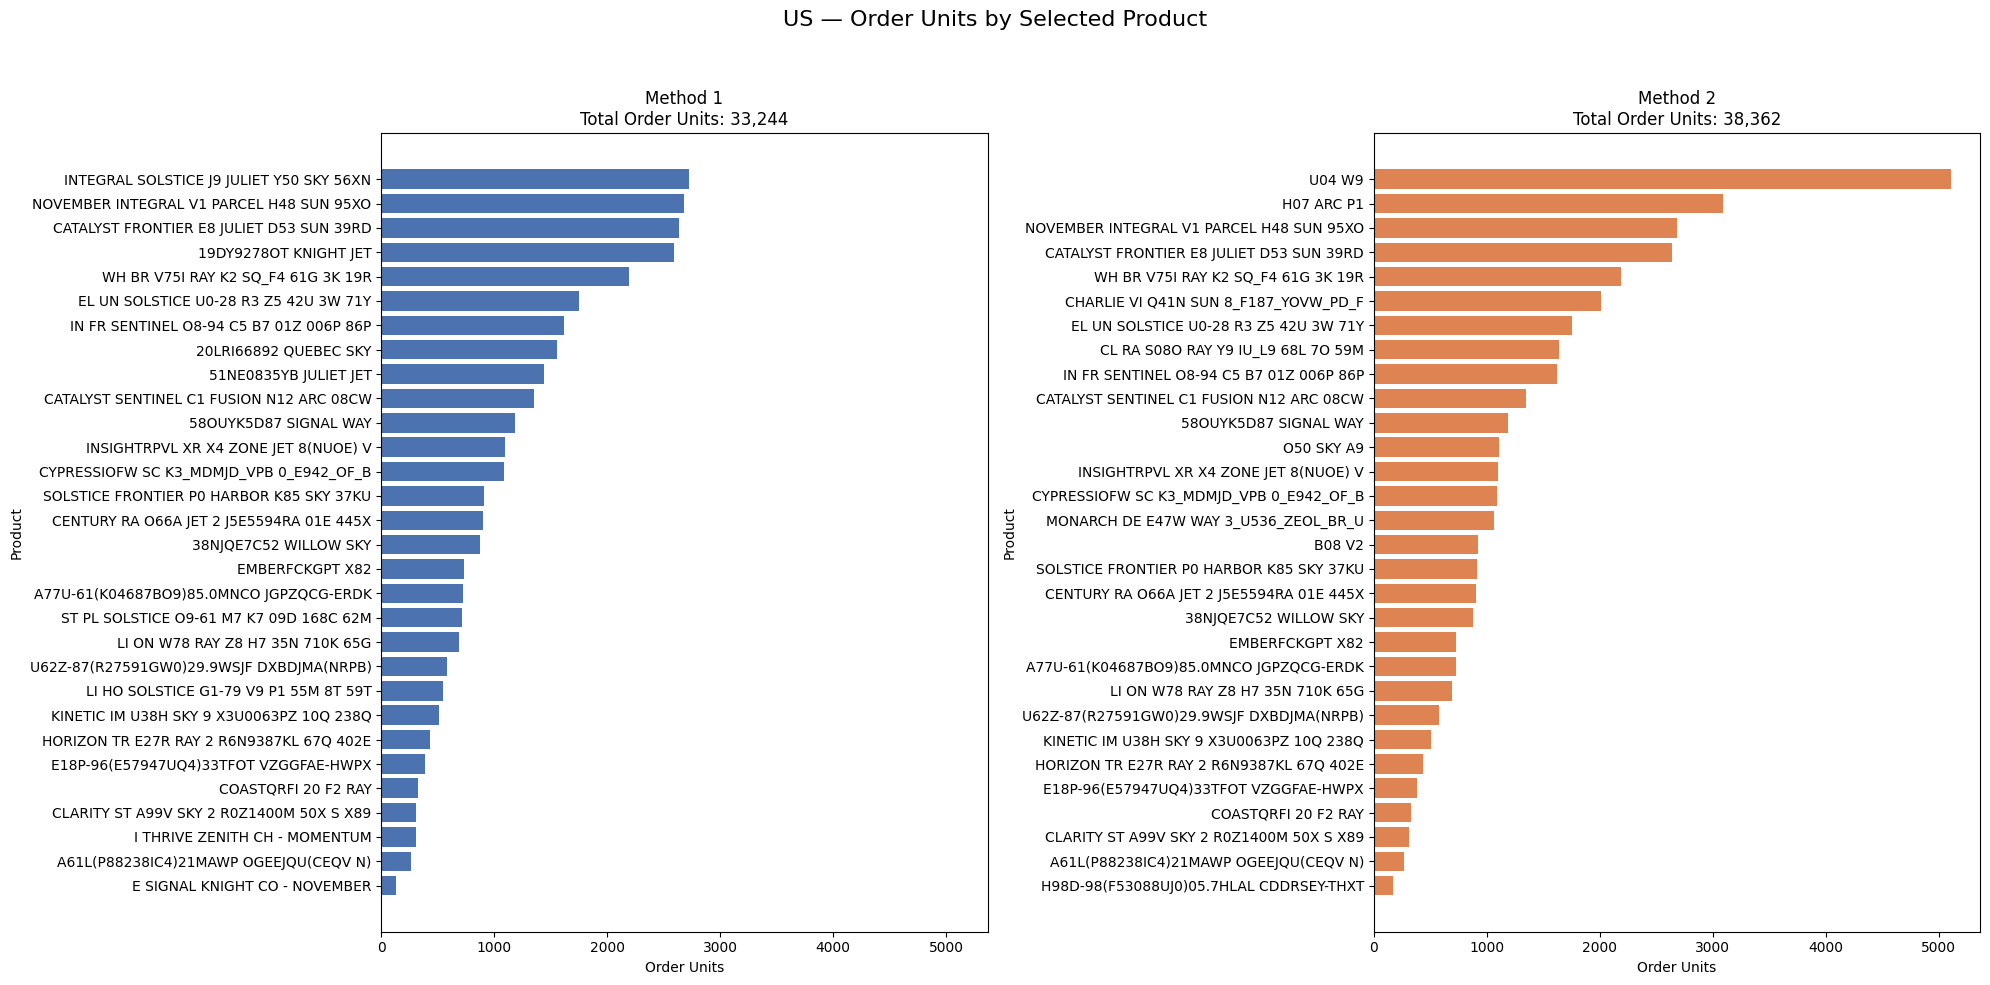

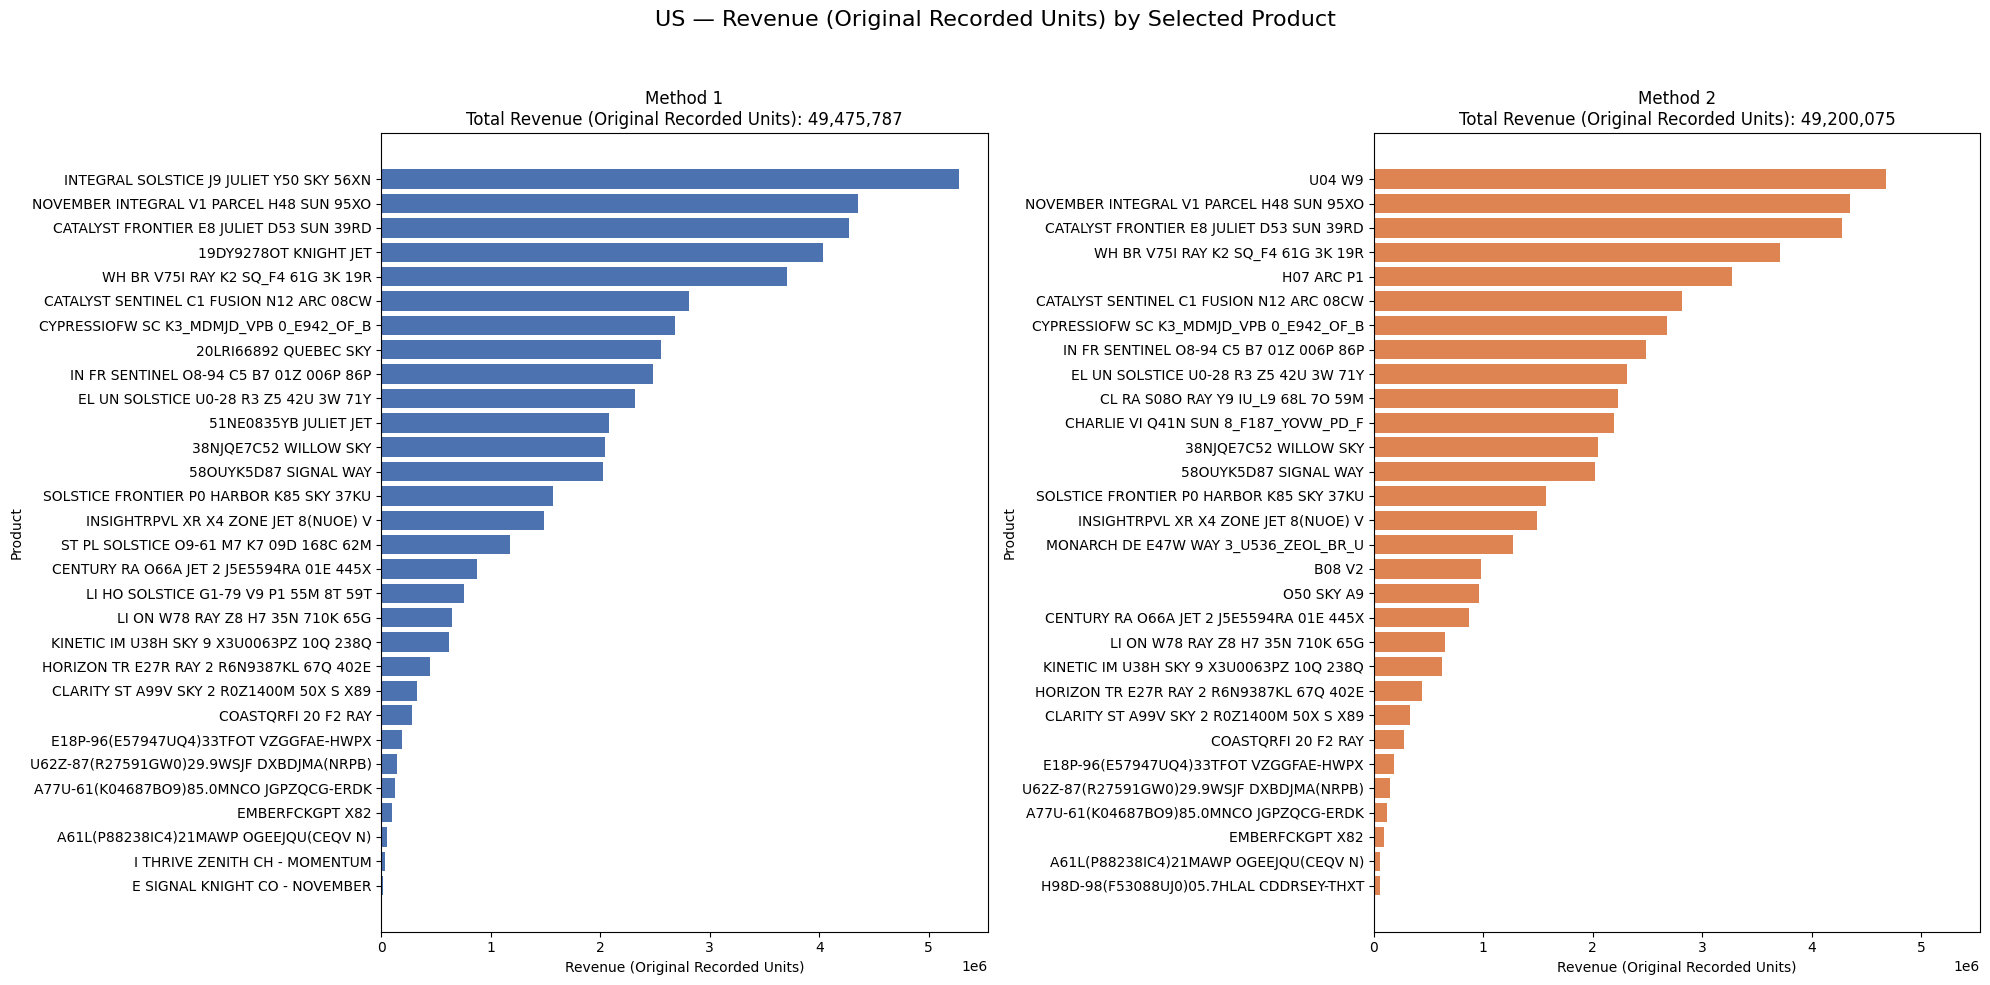

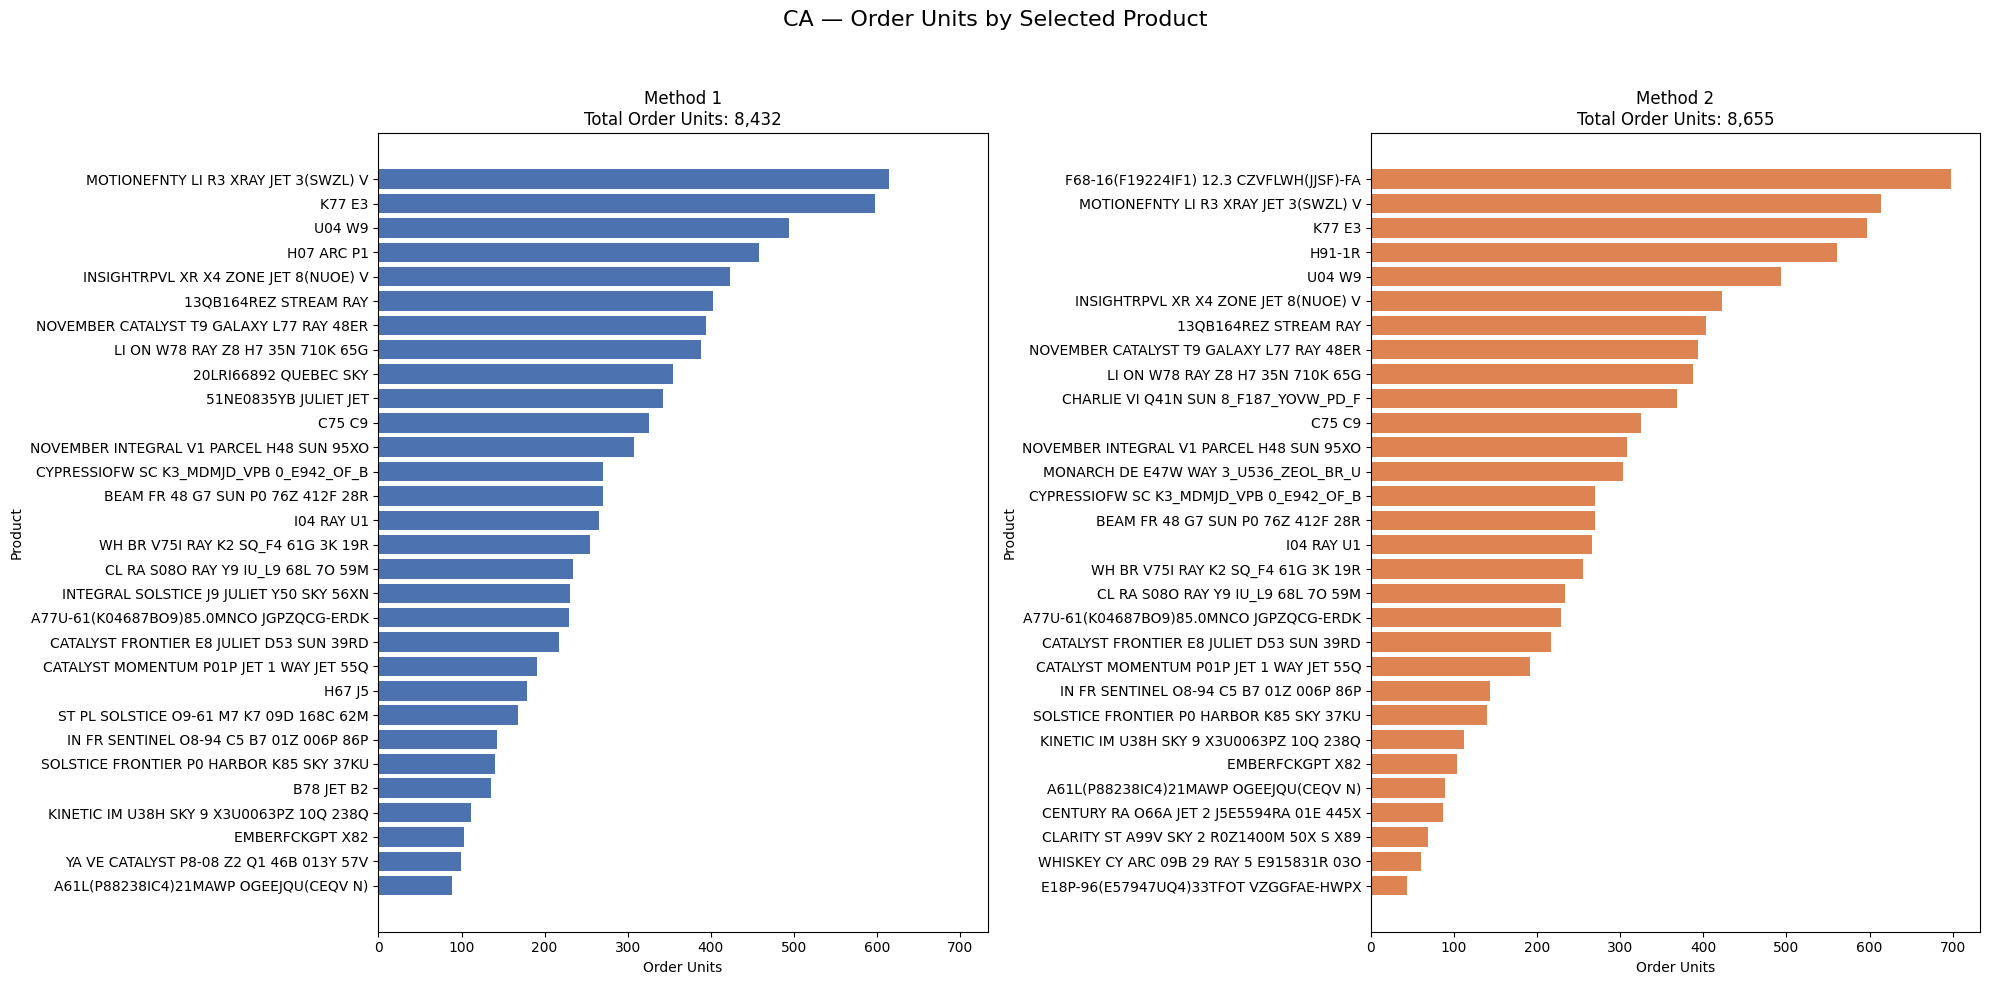

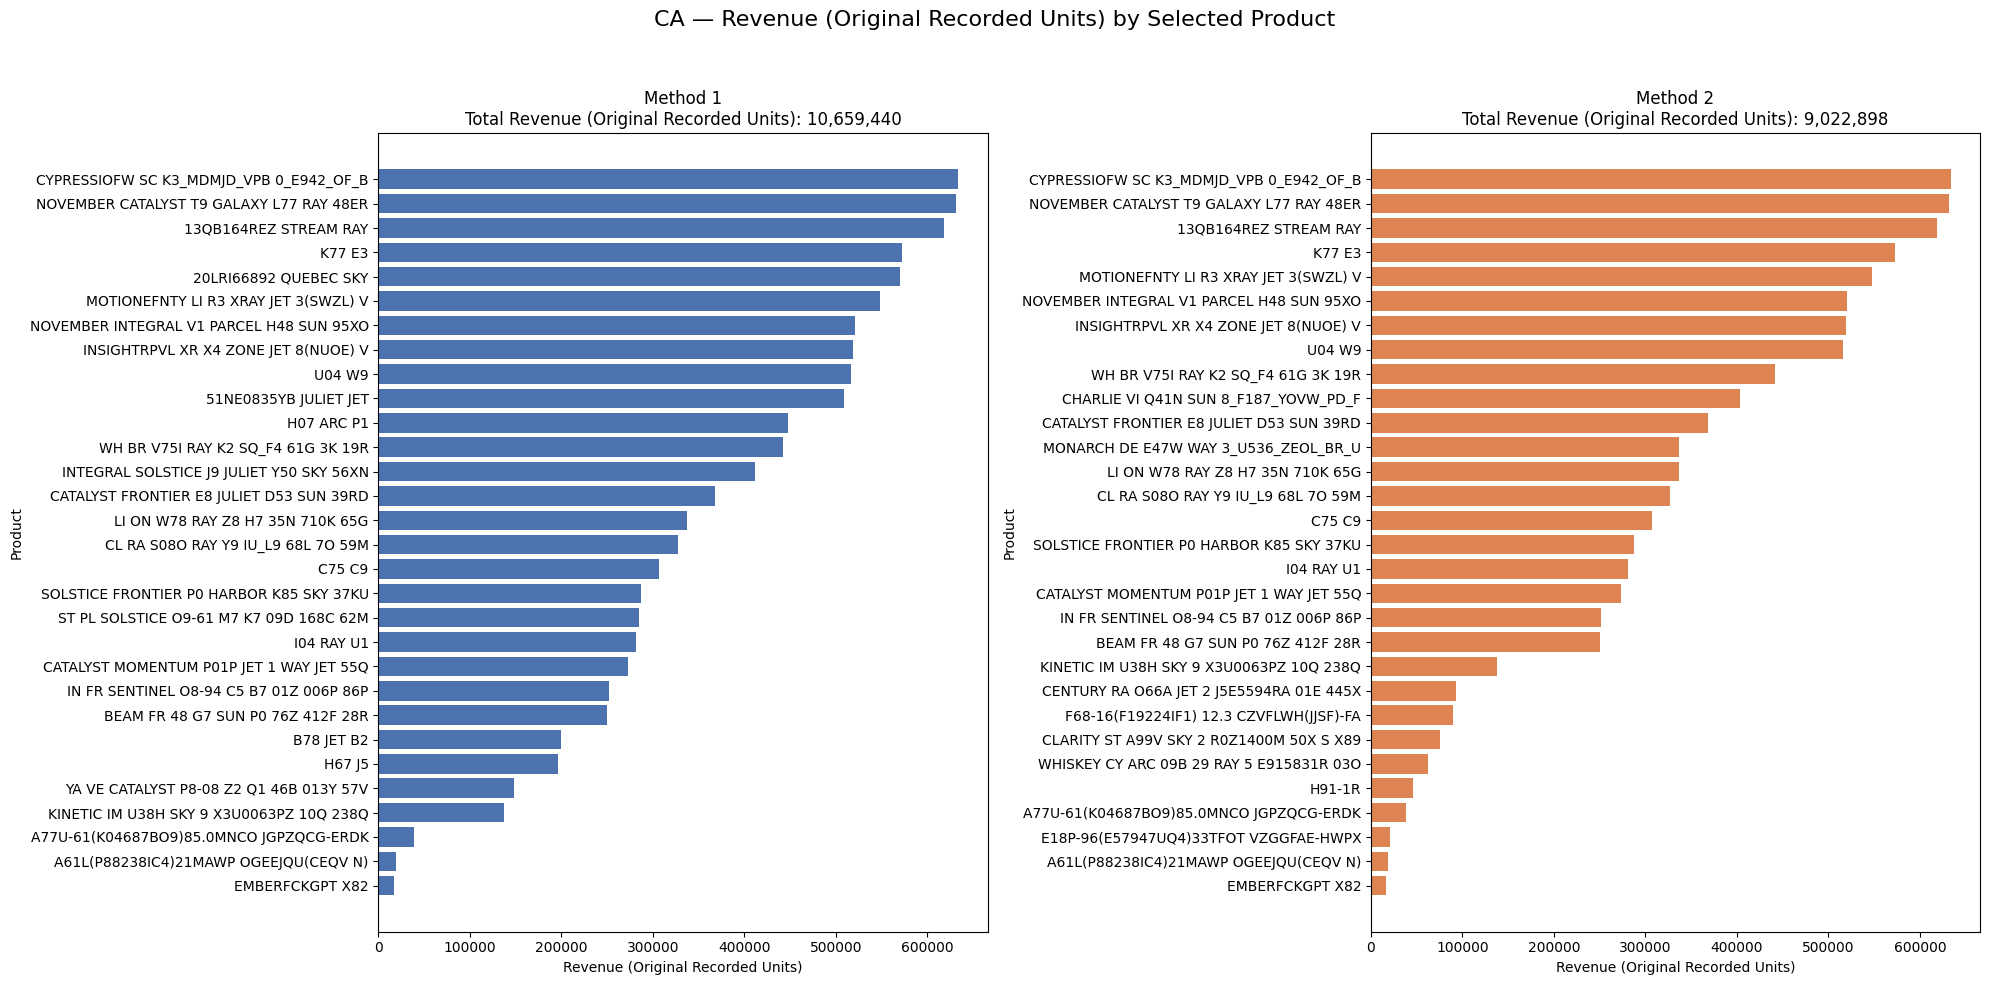

In [15]:
def plot_method_comparison(country, method1, method2, metric, label):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10), sharex=True)

    comparisons = [
        ("Method 1", method1, "#4C72B0"),
        ("Method 2", method2, "#DD8452"),
    ]

    max_value = max(method1[metric].max(), method2[metric].max())

    for ax, (method_name, summary, color) in zip(axes, comparisons):
        plot_df = summary.sort_values(metric, ascending=True)
        positions = np.arange(len(plot_df))

        ax.barh(positions, plot_df[metric], color=color)
        ax.set_yticks(positions)
        ax.set_yticklabels(plot_df["product_name"])
        ax.set_title(f"{method_name}\nTotal {label}: {plot_df[metric].sum():,.0f}")
        ax.set_xlabel(label)
        ax.set_ylabel("Product")
        ax.set_xlim(0, max_value * 1.05)

    fig.suptitle(f"{country} — {label} by Selected Product", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


for country in ["US", "CA"]:
    result = country_results[country]
    method1 = result["method1_top30_products"]
    method2 = result["method2_top6_each_family"]

    if method1.empty or method2.empty:
        print(f"{country}: insufficient candidates for method comparison.")
        continue

    plot_method_comparison(
        country,
        method1,
        method2,
        metric="order_units",
        label="Order Units",
    )

    plot_method_comparison(
        country,
        method1,
        method2,
        metric="revenue",
        label="Revenue (Original Recorded Units)",
    )

# Method 1 is selected for both countries because its selected products
# have higher total recent revenue and order units than Method 2.
# Subsequent pricing analysis uses each country's Method 1 Top30 products.

Based on the comparison above, we select Method 2 for the US to prioritize sales volume and Method 1 for Canada to prioritize revenue coverage. These selections define the country-specific product sets used in subsequent pricing analysis.

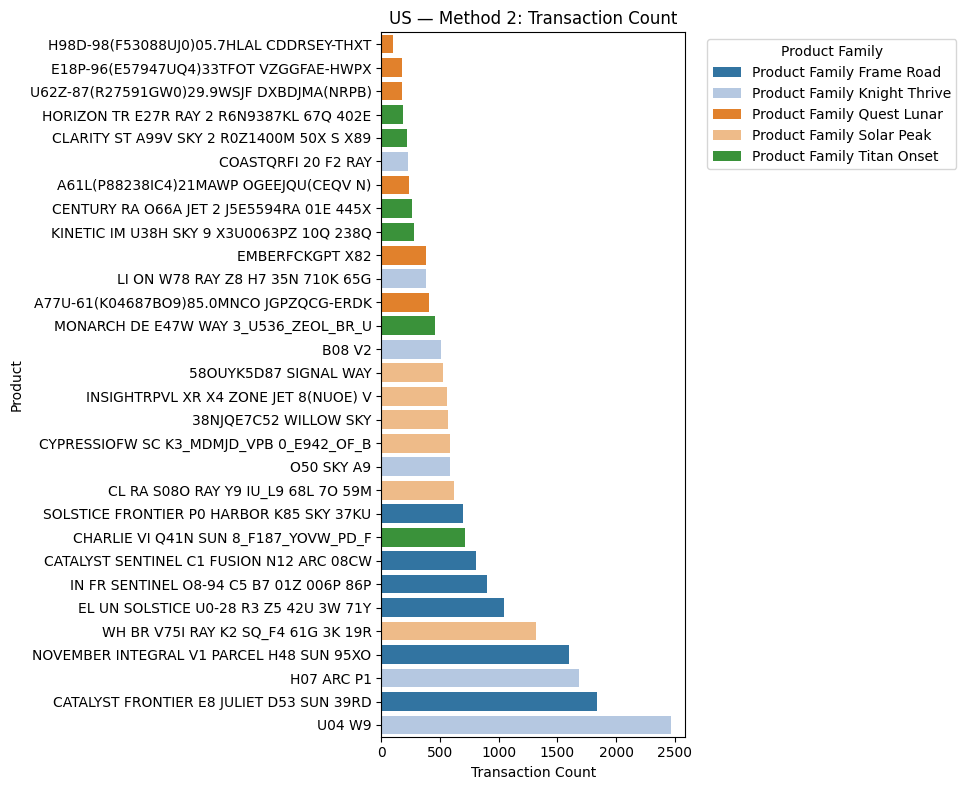

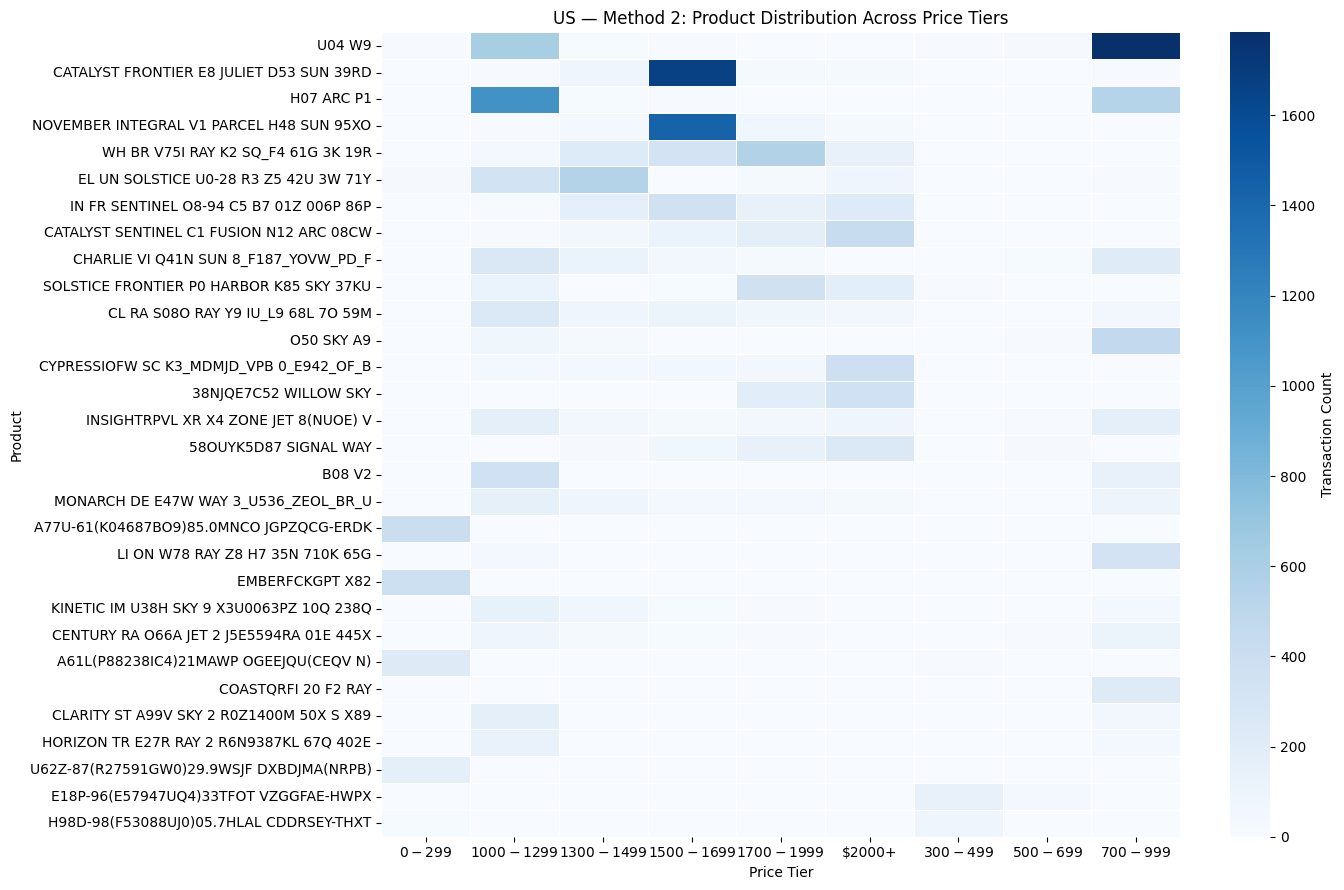

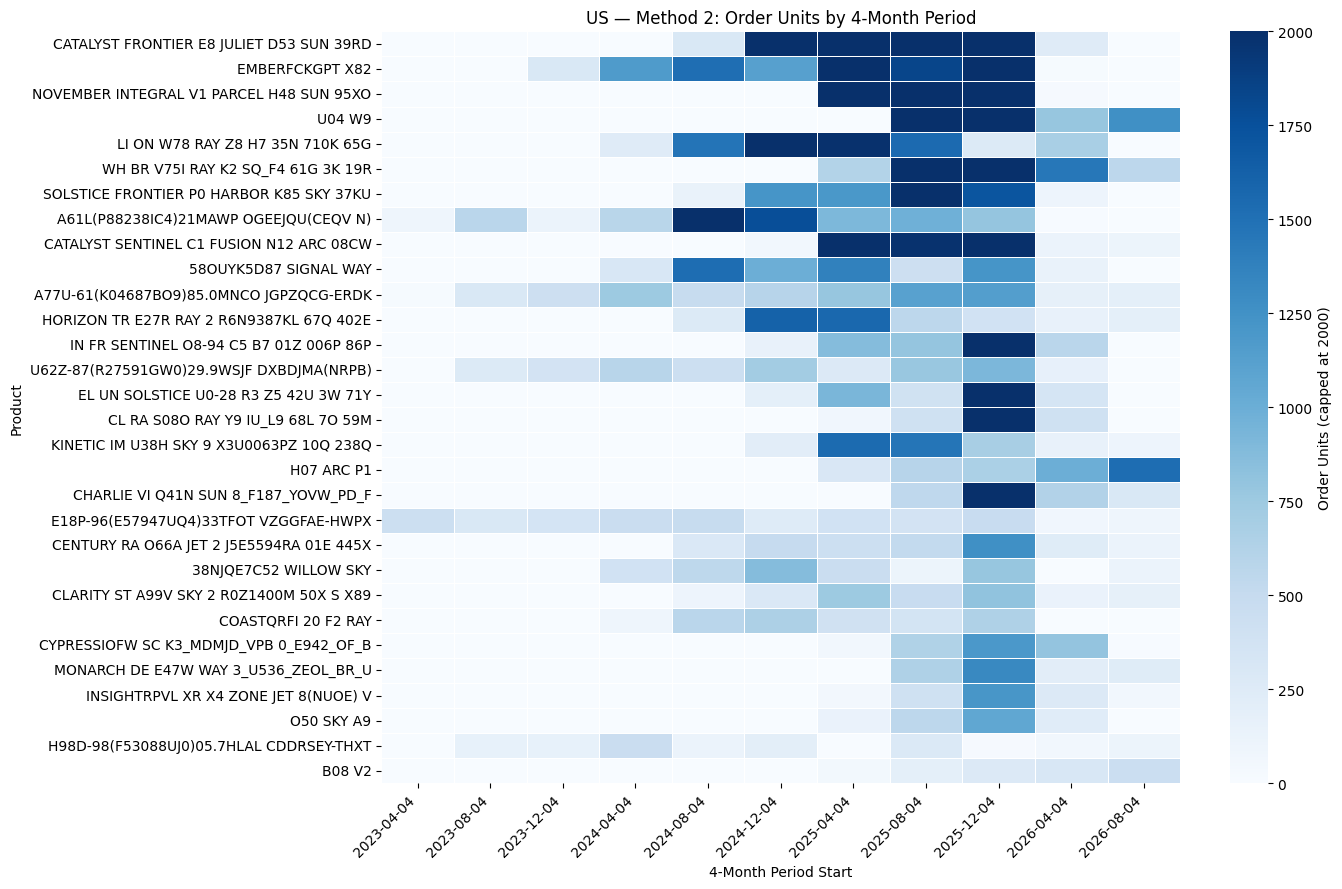

In [ ]:
# US — Method 2
us_products = country_results["US"]["method2_top6_each_family"]

us_core = pricing_eda_core[pricing_eda_core["country"].eq("US")].copy()

us_selected_recent = us_core[
    us_core["pricing_date"].ge(six_month_start)
    & us_core["product_name"].isin(us_products["product_name"])
].copy()

us_family_order = sorted(us_products["product_family"].dropna().unique())
us_family_palette = dict(
    zip(
        us_family_order,
        sns.color_palette("tab20", n_colors=len(us_family_order)),
    )
)

plot_transaction_count_bars(
    us_products,
    "US — Method 2",
    us_family_palette,
    us_family_order,
)

plot_price_tier_heatmap(
    us_selected_recent,
    "US — Method 2",
)

us_period_summary = check_product_period_coverage(
    us_core,
    us_products["product_name"],
)

plot_period_units_heatmap(
    us_period_summary,
    "US — Method 2",
)

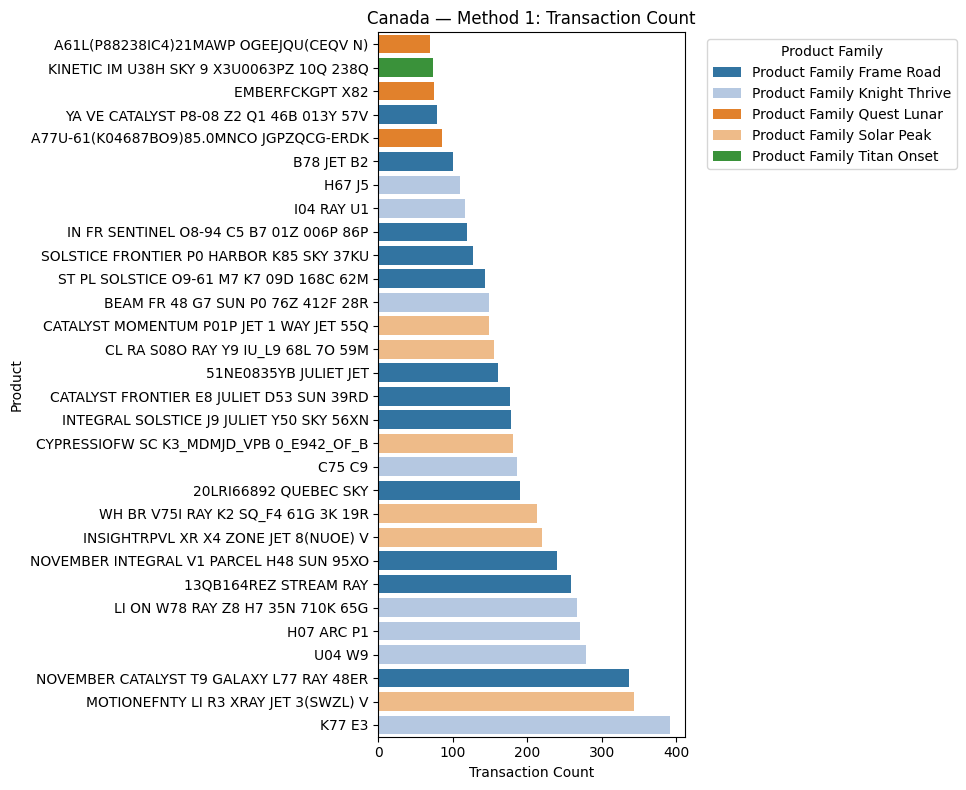

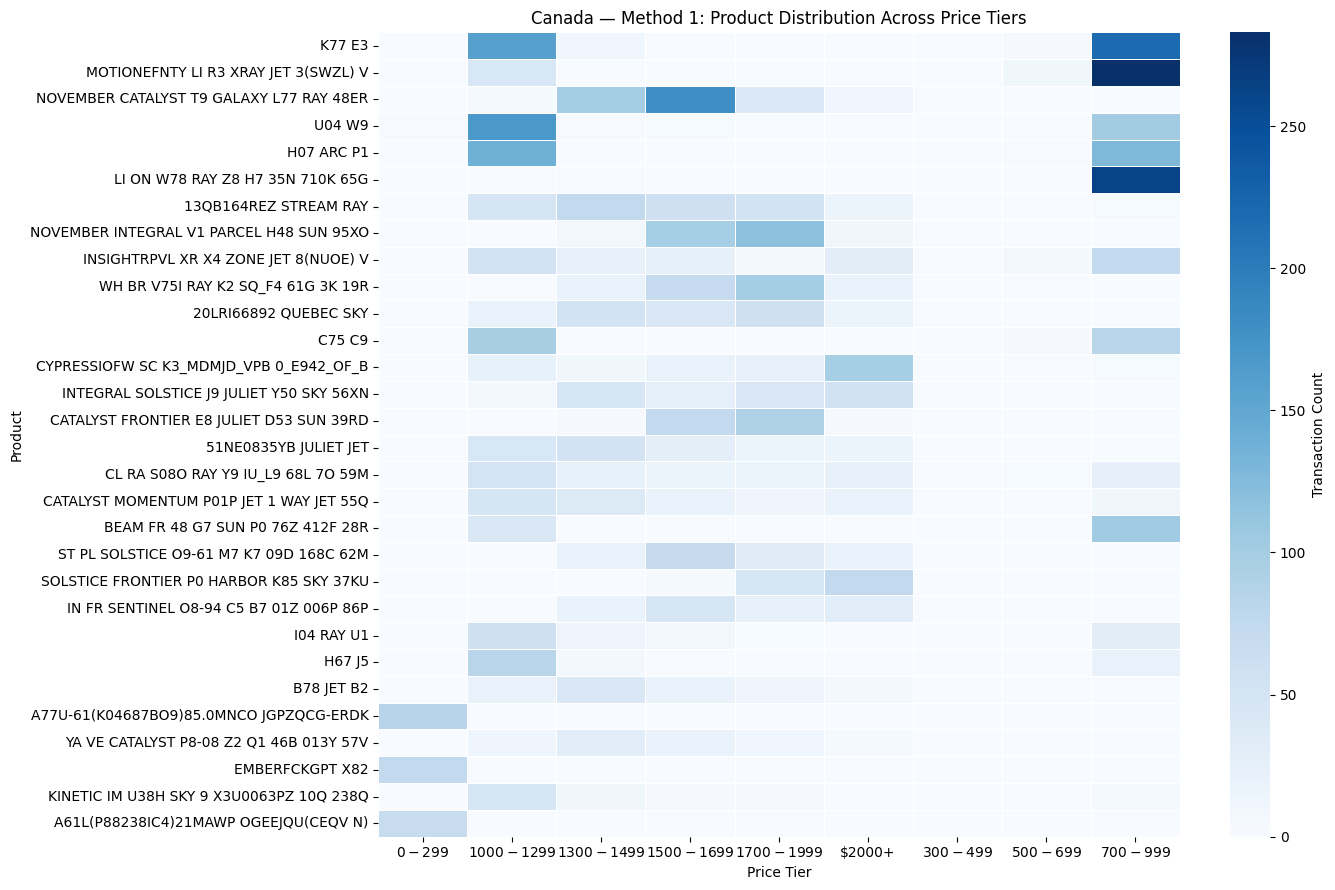

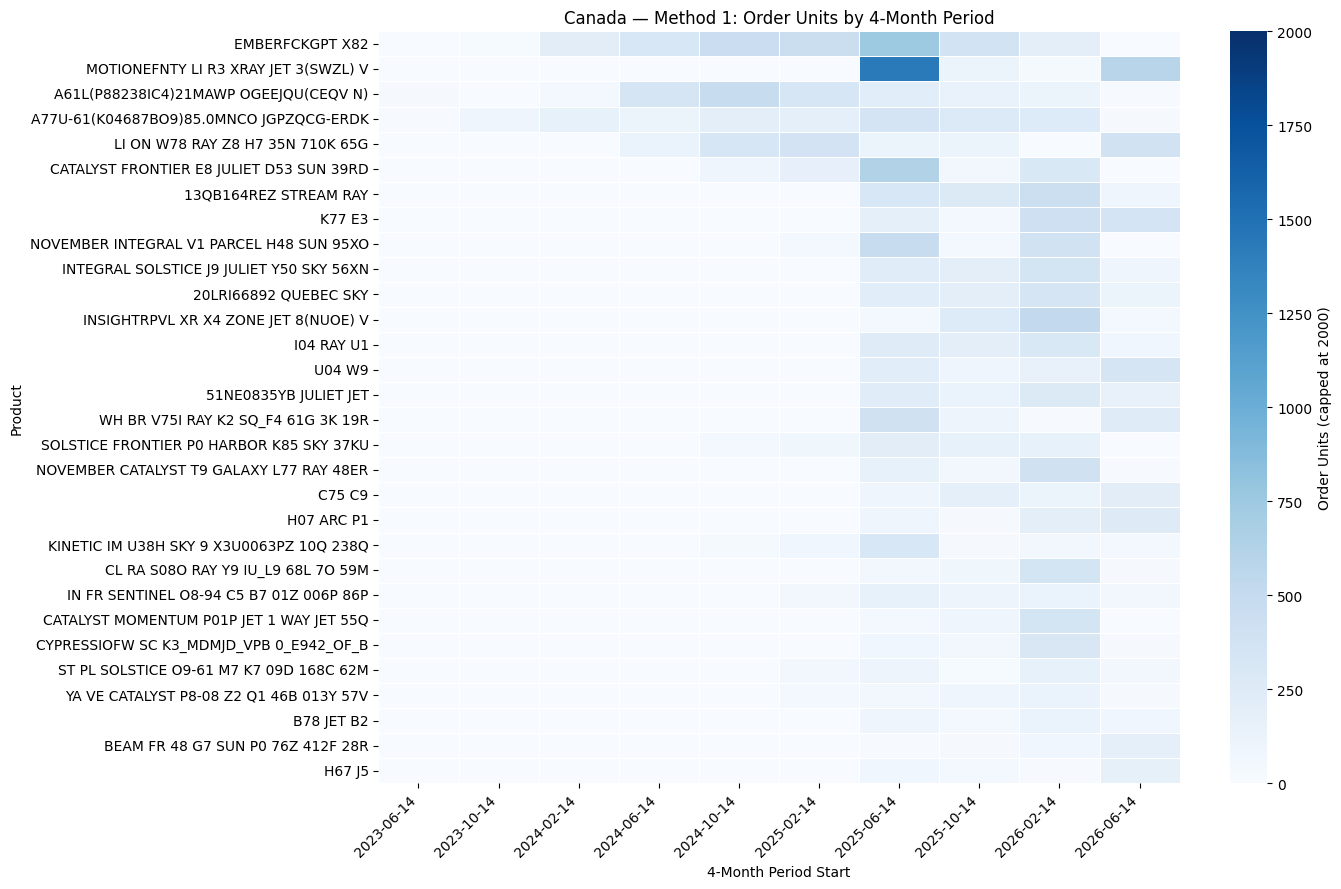

In [ ]:
# Canada — Method 1
ca_products = country_results["CA"]["method1_top30_products"]

ca_core = pricing_eda_core[pricing_eda_core["country"].eq("CA")].copy()

ca_selected_recent = ca_core[
    ca_core["pricing_date"].ge(six_month_start)
    & ca_core["product_name"].isin(ca_products["product_name"])
].copy()

ca_family_order = sorted(ca_products["product_family"].dropna().unique())
ca_family_palette = dict(
    zip(
        ca_family_order,
        sns.color_palette("tab20", n_colors=len(ca_family_order)),
    )
)

plot_transaction_count_bars(
    ca_products,
    "Canada — Method 1",
    ca_family_palette,
    ca_family_order,
)

plot_price_tier_heatmap(
    ca_selected_recent,
    "Canada — Method 1",
)

ca_period_summary = check_product_period_coverage(
    ca_core,
    ca_products["product_name"],
)

plot_period_units_heatmap(
    ca_period_summary,
    "Canada — Method 1",
)

### 8. Export Selected Product Transactions
Export cleaned transaction-level data for the selected products in each country, using Method 2 for the US and Method 1 for Canada. Each file includes the full available history for subsequent pricing analysis.

In [ ]:
# Export full-history transactions for each country's selected products
output_dir = project_dir / "pricing_eda_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

country_methods = {
    "US": "method2_top6_each_family",
    "CA": "method1_top30_products",
}

for country, method_key in country_methods.items():
    selected_products = country_results[country][method_key]

    # Match the same product grouping keys used during selection
    product_keys = ["product_name", "product_family", "product_type"]

    selected_keys = selected_products[product_keys].drop_duplicates()

    country_transactions = pricing_eda_core[pricing_eda_core["country"].eq(country)]

    export_data = country_transactions.merge(
        selected_keys,
        on=product_keys,
        how="inner",
        validate="many_to_one",
    )

    file_path = output_dir / f"{country}_selected_top30_transactions.csv"
    export_data.to_csv(file_path, index=False)

    print(
        f"{country}: exported {len(export_data):,} transaction rows "
        f"for {len(selected_keys)} selected product groups."
    )
    print(f"Saved to: {file_path}")

US: exported 89,086 transaction rows for 30 selected product groups.
Saved to: /Users/AustinZhang/Desktop/Capstone/pricing_eda_outputs/US_selected_top30_transactions.csv
CA: exported 17,732 transaction rows for 30 selected product groups.
Saved to: /Users/AustinZhang/Desktop/Capstone/pricing_eda_outputs/CA_selected_top30_transactions.csv
